# Recipe 4 — Flood & Cyclone Trends in South Asia: Seasonality, Trends, Bias and Climate Drivers

:::{admonition} Recipe Overview
:class: important

| | |
|---|---|
| **Goal** | Build a defensible time-series analysis of flood and tropical-cyclone disasters in South Asia (2000–2025): diagnose source coverage, quantify seasonality, test for trends in *occurrence* and *impact*, relate them to ENSO/IOD, and forecast monthly activity out-of-sample. |
| **Montandon data** | Event collections from EM-DAT, GDACS, GLIDE, DesInventar, IDMC, IFRC, CEMS; `emdat-impacts`; `ibtracs-events` {cite}`emdat,gdacs,glide,idmc,ibtracs` |
| **External data** | World Bank population (WDI); NOAA PSL Oceanic Niño Index (ONI) and Dipole Mode Index (DMI) |
| **Methods** | Circular statistics, robust STL {cite}`stl_decomposition`, Poisson / negative-binomial GLMs, Hamed–Rao modified Mann–Kendall {cite}`mann_kendall,hamed_rao`, Sen's slope {cite}`sen_slope`, out-of-sample forecast verification |
| **Difficulty** | Intermediate → Advanced |
| **Time** | 30 min |
:::

**The central lesson.** Montandon deliberately stores the *same* disasters as seen by
different organisations. That is its strength, but it means **an item count is not an
event count**, and each source's coverage changes over time. Earlier versions of this
recipe pooled GDACS + EM-DAT + GLIDE items and reported a "significant increasing flood
trend". Below we show that this trend is mostly an artefact of catalogue coverage, and
then do the analysis properly.

## Environment Setup

::::{tab-set}
:::{tab-item} Binder / local
Dependencies come from the repository (`uv sync` or `pip install -r requirements.txt`).
Set your token once before launching Jupyter:
```bash
export MONTANDON_API_TOKEN='your_token_here'   # from https://goadmin.ifrc.org/
```
:::
:::{tab-item} Google Colab
Run this first:
```python
!pip install -q pystac-client pandas matplotlib seaborn statsmodels pymannkendall scipy scikit-learn shapely
import os; from getpass import getpass
os.environ.setdefault('MONTANDON_API_TOKEN', getpass('Montandon API token: '))
```
The first code cell below downloads the shared helper module `montandon_utils.py`
automatically when it is not next to the notebook.
:::
::::

:::{note}
All recipes query **production** (`https://montandon-eoapi.ifrc.org/stac`).
Set `MONTANDON_API_URL` to the staging URL only for testing.
:::

In [1]:
# Shared helpers (connection, paging, flattening, hazard families, de-duplication)
import pathlib, urllib.request
if not pathlib.Path("montandon_utils.py").exists():  # e.g. on Colab
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/IFRCGo/montandon-notebooks/main/book/notebooks/montandon_utils.py",
        "montandon_utils.py")
import montandon_utils as mu

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import pymannkendall as mk
from scipy import stats
from statsmodels.tsa.seasonal import STL
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
client = mu.connect()

Connected to 'Montandon STAC API' (production: https://montandon-eoapi.ifrc.org/stac)


## Step 1 — Study design

* **Region** — the eight SAARC countries, selected by **ISO3 country code** (`a_overlaps` on
  `monty:country_codes`), not by a bounding box. A box such as `[60, 5, 100, 37]` silently
  includes parts of China, Myanmar and Central Asia.
* **Hazards** — the shared helper maps GLIDE, EM-DAT and UNDRR-ISC 2020/2025 codes to one
  *hazard family* (`mu.HAZARD_FAMILIES`), so a flood is a flood whichever taxonomy a source uses.
* **Period** — 2000–2025, i.e. 26 complete years.

In [3]:
COUNTRIES = {"AFG": "Afghanistan", "BGD": "Bangladesh", "BTN": "Bhutan", "IND": "India",
             "LKA": "Sri Lanka", "MDV": "Maldives", "NPL": "Nepal", "PAK": "Pakistan"}
START, END = "2000-01-01", "2025-12-31"
YEARS = np.arange(2000, 2026)
FAMILIES = ["flood", "tropical_cyclone"]

event_collections = sorted(c.id for c in client.get_collections() if c.id.endswith("-events"))
print("Event collections:", ", ".join(event_collections))
print("Hazard codes used:", len(mu.codes_for(*FAMILIES)))

Event collections: cems-events, charter-events, desinventar-events, emdat-events, gdacs-events, gfd-events, glide-events, ibtracs-events, idmc-gidd-events, idmc-idu-events, ifrcevent-events, pdc-events, usgs-events
Hazard codes used: 36


## Step 2 — Fetch every event collection with one server-side filter

The CQL2 filter combines hazard codes, countries and dates, and the STAC *fields*
extension downloads only the properties we need. That keeps each request to a few seconds
even for thousands of items. `mu.search` follows every `next` link, so **nothing is
silently truncated**. The original recipe capped results with `max_items`.

In [4]:
flt = mu.cql_and(mu.hazard_filter(mu.codes_for(*FAMILIES)),
                 mu.country_filter(COUNTRIES), mu.time_filter(START, END))
FIELDS = ["id", "collection", "properties.datetime", "properties.title",
          "properties.monty:hazard_codes", "properties.monty:country_codes",
          "properties.monty:corr_id", "properties.roles"]

events = pd.concat([mu.to_frame(mu.search([c], filter=flt, fields=FIELDS)) for c in event_collections],
                   ignore_index=True)
events = events[events["hazard_family"].isin(FAMILIES)].copy()
events["year"] = events["datetime"].dt.year
events["month"] = events["datetime"].dt.month
events.groupby(["collection", "hazard_family"]).size().unstack(fill_value=0)

  2 items from cems-events (0.3s)


  3 items from charter-events (0.3s)


  5,130 items from desinventar-events (8.0s)


  628 items from emdat-events (1.1s)


  1,171 items from gdacs-events (2.1s)


  67 items from gfd-events (0.4s)


... (4 outputs left out)

  103 items from ifrcevent-events (0.4s)


  2,212 items from pdc-events (4.2s)


  0 items from usgs-events (0.4s)


hazard_family,flood,tropical_cyclone
collection,,
cems-events,2,0
charter-events,3,0
desinventar-events,5083,47
emdat-events,533,95
gdacs-events,813,358
gfd-events,67,0
glide-events,268,60
ibtracs-events,0,161
idmc-gidd-events,1889,47


## Step 3 — Diagnose catalogue coverage before computing any trend

Each source has its own inclusion rules, start date and reporting practice:

| Source | What enters the catalogue |
|--------|---------------------------|
| EM-DAT | Disasters with ≥ 10 deaths, ≥ 100 affected, an emergency declaration or an international appeal |
| GDACS | Automatically detected hazards (flood module driven by media and models) |
| GLIDE | Events given a GLIDE number by participating agencies |
| DesInventar | Sub-national loss records reported by national databases |
| IDMC | Displacement events (systematic monitoring since 2008, expanded since 2018) |
| CEMS / Charter | Satellite-mapping activations (since 2012/2000; in Montandon since 2023) |

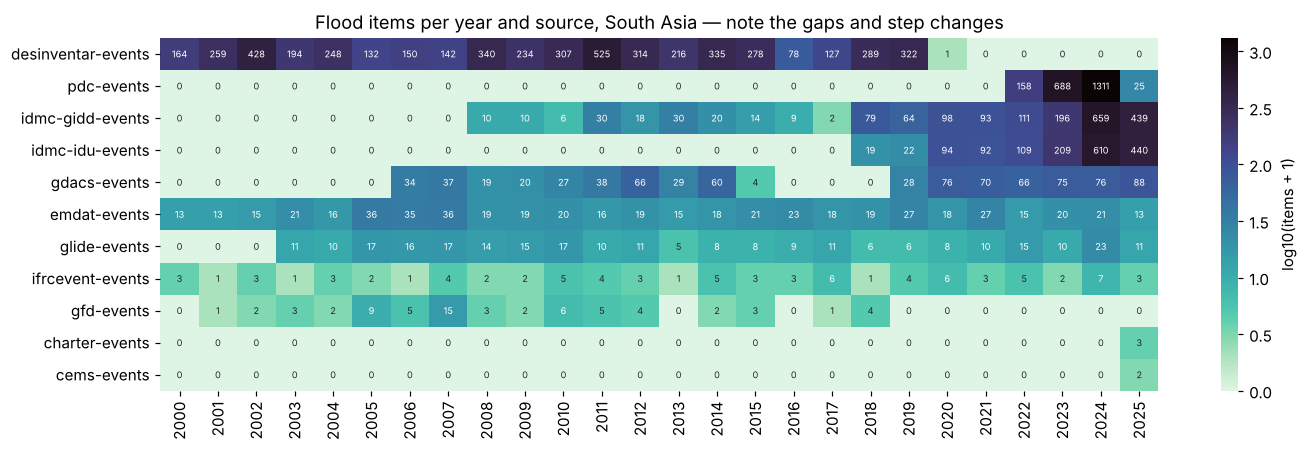

In [5]:
floods = events[events.hazard_family == "flood"]
cov = (floods.groupby(["collection", "year"]).size().unstack(fill_value=0)
             .reindex(columns=YEARS, fill_value=0))
cov = cov.loc[cov.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 4.2))
sns.heatmap(np.log10(cov + 1), cmap="mako_r", cbar_kws={"label": "log10(items + 1)"}, ax=ax,
            annot=cov, fmt="d", annot_kws={"size": 6})
ax.set(title="Flood items per year and source, South Asia — note the gaps and step changes",
       xlabel="", ylabel="")
plt.tight_layout(); plt.show()

The heatmap shows why pooling is unsafe:

* **GDACS** has almost no South-Asian flood events for 2015 and none for 2016–2018, then 70–90 per year.
* **PDC** only appears from 2022, and then with hundreds of records per year.
* **IDMC** grows from a handful to hundreds per year after 2018, as its monitoring expanded.
* **DesInventar** stops after 2020, when national uploads end.
* **EM-DAT** is the most stable series because it applies the same impact thresholds throughout.

### Reproducing (and refuting) the pooled trend

Below we run the original recipe's approach (GDACS + EM-DAT + GLIDE pooled, 2014–2024, plain
Mann–Kendall), then the same test on each source separately over 2000–2025.

In [6]:
def mk_row(y, label):
    r = mk.original_test(y)
    return {"series": label, "years": f"{y.index.min()}–{y.index.max()}", "trend": r.trend,
            "p": round(r.p, 4), "Sen slope / yr": round(r.slope, 2)}

pooled = (floods[floods.collection.isin(["gdacs-events", "emdat-events", "glide-events"])]
          .groupby("year").size().reindex(range(2014, 2025), fill_value=0))
rows = [mk_row(pooled, "POOLED gdacs+emdat+glide (original recipe)")]
for c in cov.index:
    y = cov.loc[c]
    if y.sum() >= 50:
        rows.append(mk_row(y, c))
pd.DataFrame(rows)

,series,years,trend,p,Sen slope / yr
0,POOLED gdacs+emdat+glide (original recipe),2014–2024,increasing,0.0430,9.67
1,desinventar-events,2000–2025,decreasing,0.0132,-8.69
2,pdc-events,2000–2025,increasing,0.0021,0.00
3,idmc-gidd-events,2000–2025,increasing,0.0000,5.00
4,idmc-idu-events,2000–2025,increasing,0.0000,1.36
5,gdacs-events,2000–2025,increasing,0.0002,3.14
6,emdat-events,2000–2025,no trend,0.6254,0.07
7,glide-events,2000–2025,no trend,0.5788,0.07
8,ifrcevent-events,2000–2025,increasing,0.0356,0.10
9,gfd-events,2000–2025,decreasing,0.0113,-0.12


The pooled 2014–2024 series appears to show a significant increase. Per source, the
"trends" point in contradictory directions and line up with the coverage changes in the
heatmap. **Conclusion:** analyse one consistently collected source at a time, and treat
cross-source comparisons as a data-quality check rather than as a signal.

For the rest of the recipe we use **EM-DAT**: its inclusion criteria are fixed, it starts
long before 2000, and it carries harmonised impact figures. EM-DAT still has reporting
bias (small events in data-poor countries are under-recorded, and recording improved
over time {cite}`jones2022`), so trends in *counts* remain partly a statement about
reporting. Impact-weighted series (Step 7) are less sensitive to this.

In [7]:
em = events[events.collection == "emdat-events"].copy()
print(em.groupby("hazard_family").size().rename("EM-DAT events 2000–2025"))
em.sort_values("datetime").tail(5)[["datetime", "title", "country_codes", "hazard_family"]]

hazard_family
flood               533
tropical_cyclone     95
Name: EM-DAT events 2000–2025, dtype: int64


,datetime,title,country_codes,hazard_family
5139,2025-10-03 00:00:00+00:00,Flood (General) in Nepal,[NPL],flood
5138,2025-10-03 00:00:00+00:00,Flood (General) in India,[IND],flood
5137,2025-10-28 00:00:00+00:00,Storm (Tropical cyclone) in India of October 2025,[IND],tropical_cyclone
5136,2025-11-27 00:00:00+00:00,Storm (Tropical cyclone) in India of November ...,[IND],tropical_cyclone
5135,2025-11-27 00:00:00+00:00,Storm (Tropical cyclone) in Sri Lanka of Novem...,[LKA],tropical_cyclone


## Step 4 — Seasonality with circular statistics

Months wrap around (December is next to January), so the *mean month* must be computed on
a circle. For each event we convert the day of year to an angle $\theta_i$ and compute the
mean resultant vector

$$
\bar{R} = \left|\frac{1}{n}\sum_i e^{i\theta_i}\right| \in [0, 1],
$$

where $\bar R \to 1$ means all events fall in the same season and $\bar R \to 0$ means no
preferred season. The **Rayleigh test** checks $H_0$: no preferred direction.

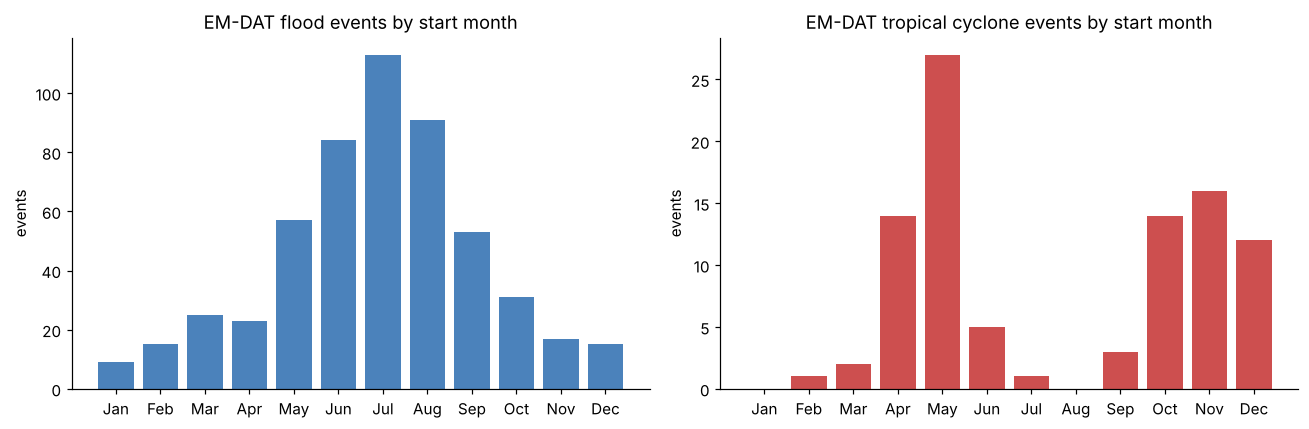

,n,mean date,R̄,Rayleigh p,pre-monsoon (Apr–Jun) share,post-monsoon (Oct–Dec) share
flood,533,15 Jul,0.5,3.7e-62,NaN,NaN
tropical_cyclone,95,03 Apr,0.06,7.4e-01,48%,44%


In [8]:
def circular_summary(dates):
    doy = dates.dt.day_of_year.to_numpy()
    theta = 2 * np.pi * doy / 365.25
    C, S = np.cos(theta).mean(), np.sin(theta).mean()
    n, R = len(theta), np.hypot(C, S)
    mean_doy = (np.arctan2(S, C) % (2 * np.pi)) * 365.25 / (2 * np.pi)
    # Rayleigh test p-value (Zar 2010, eq. 27.4)
    p = np.exp(np.sqrt(1 + 4 * n + 4 * (n**2 - (n * R) ** 2)) - (1 + 2 * n))
    peak = pd.Timestamp("2001-01-01") + pd.Timedelta(days=float(mean_doy) - 1)
    return {"n": n, "mean date": peak.strftime("%d %b"), "R̄": round(R, 2), "Rayleigh p": f"{p:.1e}"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
summary = {}
for ax, (fam, colour) in zip(axes, [("flood", "#2b6cb0"), ("tropical_cyclone", "#c53030")]):
    d = em[em.hazard_family == fam]
    m = d.month.value_counts().reindex(range(1, 13), fill_value=0)
    ax.bar(MONTHS, m.values, color=colour, alpha=.85)
    ax.set(title=f"EM-DAT {fam.replace('_', ' ')} events by start month", ylabel="events")
    summary[fam] = circular_summary(d.datetime)
plt.tight_layout(); plt.show()

tc = em[em.hazard_family == "tropical_cyclone"]
summary["tropical_cyclone"]["pre-monsoon (Apr–Jun) share"] = f"{tc.month.between(4, 6).mean():.0%}"
summary["tropical_cyclone"]["post-monsoon (Oct–Dec) share"] = f"{tc.month.between(10, 12).mean():.0%}"
pd.DataFrame(summary).T

Floods are strongly concentrated in the south-west monsoon (high $\bar R$, mean date in
July–August). Cyclone disasters are **bimodal**: they cluster before the monsoon onset
(April–June) and after its withdrawal (October–December). During the monsoon, strong
vertical wind shear over the Bay of Bengal suppresses cyclone formation. A single mean
direction is therefore a poor summary for cyclones, and $\bar R$ is correspondingly low.

## Step 5 — STL decomposition of monthly flood disasters

**STL** (Seasonal–Trend decomposition using Loess) {cite}`stl_decomposition` splits the series into
trend $T_t$, seasonal $S_t$ and remainder $R_t$. The original recipe called
`seasonal_decompose`, a classical moving-average method that loses six months at each end and
forces a fixed seasonal shape; `statsmodels.tsa.seasonal.STL` is the real STL. With
`robust=True`, extreme months (e.g. the 2022 Pakistan floods) are down-weighted instead of
distorting the trend.

The strength of seasonality and trend {cite}`wang_hyndman` are

$$F_S = \max\left(0, 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right),\quad
  F_T = \max\left(0, 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(T_t + R_t)}\right).$$

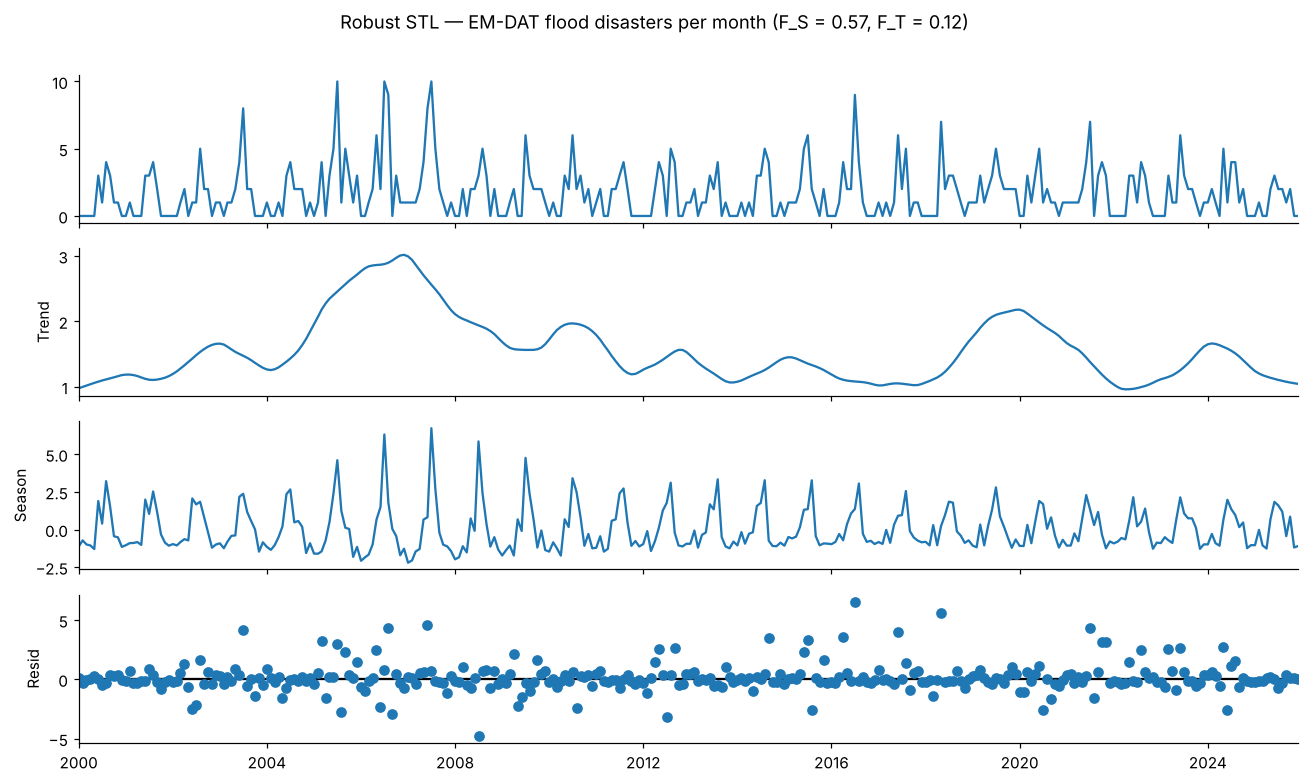

In [9]:
monthly = (em[em.hazard_family == "flood"].set_index("datetime").resample("MS").size()
           .reindex(pd.date_range(START, END, freq="MS", tz="UTC"), fill_value=0))
monthly.index = monthly.index.tz_localize(None)
res = STL(monthly, period=12, robust=True).fit()

F_S = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
F_T = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())
fig = res.plot(); fig.set_size_inches(12, 7)
fig.suptitle(f"Robust STL — EM-DAT flood disasters per month (F_S = {F_S:.2f}, F_T = {F_T:.2f})", y=1.01)
plt.tight_layout(); plt.show()

Seasonality is strong ($F_S$ well above 0.5) and the trend component is weak. The STL trend
rises in the mid-2000s, a period of improved recording, and then levels off. The large
remainders flag unusually active monsoons.

## Step 6 — Testing for trends in annual disaster counts

Annual counts are **counts**, so a Poisson or negative-binomial generalised linear model is
the natural regression. The Poisson model assumes variance = mean, which disaster counts
almost never satisfy. We check the dispersion statistic (Pearson $\chi^2$ / df) and switch
to a negative-binomial model when it exceeds 1. We also report the **Hamed–Rao modified
Mann–Kendall** test {cite}`hamed_rao`, which corrects the variance of the MK statistic for
serial correlation. The plain MK test assumes independent years and over-states significance
when years are autocorrelated.

In [10]:
def count_trend(y, label):
    yrs = y.index.to_numpy()
    X = sm.add_constant((yrs - yrs.mean()) / 10)            # slope per decade
    pois = sm.GLM(y.to_numpy(), X, family=sm.families.Poisson()).fit()
    dispersion = pois.pearson_chi2 / pois.df_resid
    nb = sm.NegativeBinomial(y.to_numpy(), X).fit(disp=0)
    model = nb if dispersion > 1.2 else pois
    b, (lo, hi) = model.params[1], model.conf_int()[1]
    hr = mk.hamed_rao_modification_test(y.to_numpy())
    return {"series": label, "mean / yr": round(y.mean(), 1), "dispersion": round(dispersion, 2),
            "model": "NegBin" if model is nb else "Poisson",
            "rate ratio / decade": f"{np.exp(b):.2f} [{np.exp(lo):.2f}, {np.exp(hi):.2f}]",
            "GLM p": round(model.pvalues[1], 3), "Hamed–Rao p": round(hr.p, 3),
            "Sen slope / yr": round(hr.slope, 2)}

annual = {fam: em[em.hazard_family == fam].groupby("year").size().reindex(YEARS, fill_value=0)
          for fam in FAMILIES}
pd.DataFrame([count_trend(annual[f], f"EM-DAT {f}") for f in FAMILIES])

,series,mean / yr,dispersion,model,rate ratio / decade,GLM p,Hamed–Rao p,Sen slope / yr
0,EM-DAT flood,20.5,2.22,NegBin,"0.97 [0.83, 1.14]",0.712,0.535,0.07
1,EM-DAT tropical_cyclone,3.7,1.08,Poisson,"1.16 [0.88, 1.51]",0.290,0.191,0.06


A rate ratio of 1 means no change. The 95 % confidence intervals are what matter here: with
26 years of noisy, overdispersed counts the intervals are wide, and we **cannot claim a
robust trend in the number of reported flood or cyclone disasters** in South Asia since 2000.

### Physical hazard vs. disaster: IBTrACS North Indian Ocean storms

Counting *disasters* mixes hazard frequency with exposure and vulnerability. Montandon also
holds the **physical** cyclone record (IBTrACS). The event description includes each storm's
lifetime maximum wind, which lets us count tropical storms (≥ 34 kt) and severe cyclones
(≥ 64 kt) in the North Indian Ocean independently of their impacts.

  469 items from ibtracs-events (0.9s)
469 systems, lifetime max wind parsed for 100%


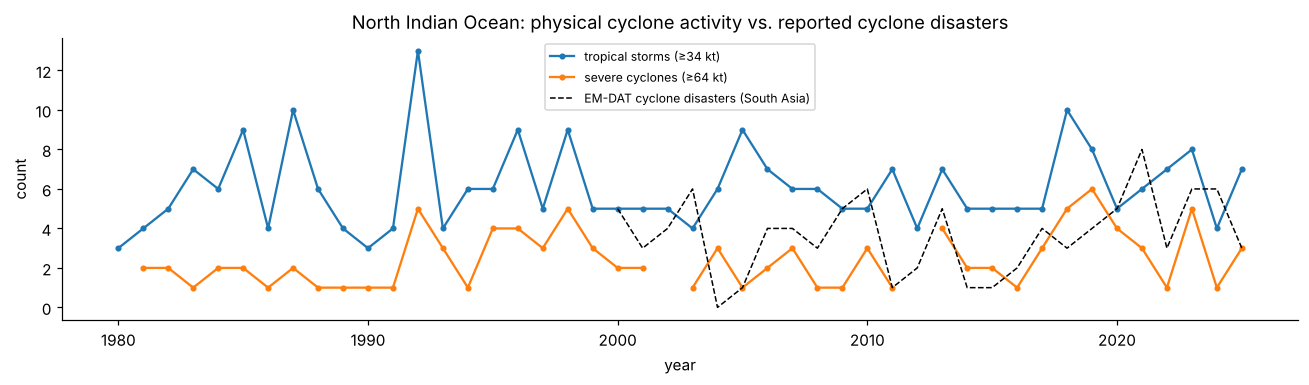

,series,years,trend,p,Sen slope / yr
0,tropical storms (≥34 kt),1980–2025,no trend,0.2235,0.0
1,severe cyclones (≥64 kt),1980–2025,no trend,0.1342,0.0


In [11]:
raw = mu.search(["ibtracs-events"], bbox=[40, 0, 100, 30], datetime="1980-01-01T00:00:00Z/2025-12-31T23:59:59Z",
                fields=["id", "collection", "properties.datetime", "properties.title",
                        "properties.description", "properties.monty:hazard_codes"])
nio = mu.to_frame(raw)
desc = pd.Series([f["properties"].get("description") or "" for f in raw])
nio["vmax_kt"] = pd.to_numeric(desc.str.extract(r"\(([\d.]+) knots\)", expand=False).to_numpy(), errors="coerce")
nio["year"] = nio.datetime.dt.year
print(f"{len(nio)} systems, lifetime max wind parsed for {nio.vmax_kt.notna().mean():.0%}")

storms = pd.DataFrame({
    "tropical storms (≥34 kt)": nio[nio.vmax_kt >= 34].groupby("year").size(),
    "severe cyclones (≥64 kt)": nio[nio.vmax_kt >= 64].groupby("year").size(),
}).reindex(range(1980, 2026), fill_value=0)
ax = storms.plot(figsize=(12, 3.6), marker="o", ms=3)
ax.plot(annual["tropical_cyclone"].index, annual["tropical_cyclone"].values, "k--", lw=1,
        label="EM-DAT cyclone disasters (South Asia)")
ax.set(title="North Indian Ocean: physical cyclone activity vs. reported cyclone disasters", ylabel="count")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
pd.DataFrame([mk_row(storms[c], c) for c in storms])

## Step 7 — Trends in impacts, normalised by population

A society can face the same number of floods while losing fewer lives if early warning,
evacuation and infrastructure improve, as global studies of declining flood vulnerability
have found {cite}`jongman2015`. To test this we need **impacts**:

1. Download EM-DAT impact records (deaths, total affected) for the same events.
2. Remove duplicate updates with `mu.latest_impacts`, so each event × country × type is counted once.
3. Divide by population (World Bank `SP.POP.TOTL`) to obtain **mortality per million**.

In [12]:
imp_flt = mu.cql_and(mu.hazard_filter(mu.codes_for(*FAMILIES)), mu.country_filter(COUNTRIES),
                     mu.time_filter(START, END),
                     mu.is_in("monty:impact_detail.type", ["death", "affected_total"]))
imp = mu.to_frame(mu.search(["emdat-impacts"], filter=imp_flt,
                            fields=FIELDS + ["properties.monty:impact_detail"]))
imp = mu.latest_impacts(imp[imp.hazard_family.isin(FAMILIES)])
imp = imp[imp.country.isin(COUNTRIES)]
imp["year"] = imp.datetime.dt.year

pop = mu.world_bank("SP.POP.TOTL", COUNTRIES, 2000, 2024)
pop_region = pop.groupby("year")["value"].sum()

deaths = imp[imp.impact_type == "death"].pivot_table(index="year", columns="hazard_family",
                                                    values="impact_value", aggfunc="sum").reindex(YEARS).fillna(0)
deaths["total"] = deaths.sum(axis=1)
rate = (deaths["total"] / pop_region * 1e6).dropna()
print(f"{len(imp):,} de-duplicated impact rows; regional population 2024: {pop_region.iloc[-1] / 1e9:.2f} bn")
deaths.astype(int).T

  1,513 items from emdat-impacts (2.5s)


1,090 de-duplicated impact rows; regional population 2024: 1.97 bn


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
hazard_family,,,,,,,,,,,,,,,,,,,,,
flood,2478,800,865,1580,2321,3160,1901,4350,1864,1807,...,1591,1895,955,2663,3615,2720,4389,2248,1734,1565
tropical_cyclone,40,283,213,151,0,24,260,4517,36,325,...,52,918,138,141,140,252,37,34,115,834
total,2518,1083,1078,1731,2321,3184,2161,8867,1900,2132,...,1643,2813,1093,2804,3755,2972,4426,2282,1849,2399


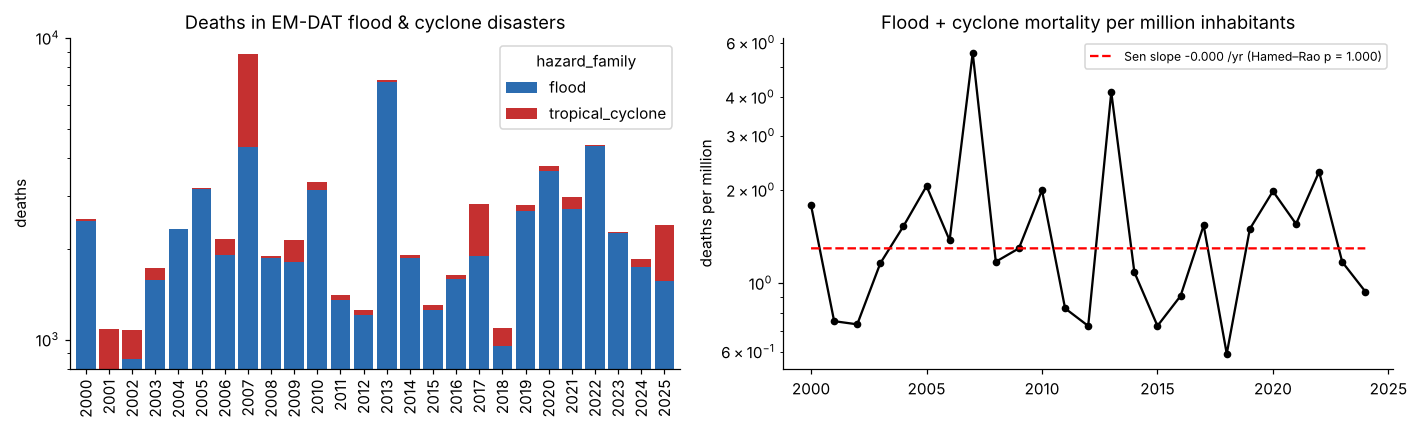

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
deaths[FAMILIES].plot.bar(stacked=True, ax=axes[0], color=["#2b6cb0", "#c53030"], width=.85)
axes[0].set(title="Deaths in EM-DAT flood & cyclone disasters", ylabel="deaths", xlabel="")
axes[0].set_yscale("log")

axes[1].plot(rate.index, rate.values, "o-", color="k", ms=4)
hr = mk.hamed_rao_modification_test(rate.to_numpy())
x = rate.index.to_numpy()
axes[1].plot(x, hr.intercept + hr.slope * np.arange(len(x)), "r--",
             label=f"Sen slope {hr.slope:+.3f} /yr (Hamed–Rao p = {hr.p:.3f})")
axes[1].set(title="Flood + cyclone mortality per million inhabitants", ylabel="deaths per million")
axes[1].set_yscale("log"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Disaster losses are heavy-tailed

Per-capita mortality is **flat**: the Kendall statistic is exactly zero (no tendency up or
down), and a log-linear fit gives about −0.2 % per year, so roughly 1–2 deaths per million
inhabitants per year throughout 2000–2024. Absolute deaths have therefore risen roughly in
line with population. This differs from the global *decline* in flood vulnerability reported
by {cite}`jongman2015`. Part of the difference may be reporting, because recording of small
deadly floods improved over the period and that can mask a real decline. That caveat is
exactly why a single source is analysed consistently here.

A handful of catastrophes dominate the totals: the 2013 Uttarakhand floods, Cyclone Sidr
(2007) and the 2010 Pakistan floods. The 2004 Indian Ocean tsunami is not included because it
is a tsunami, not a flood or cyclone. Means and sums are therefore unstable. The Lorenz curve
below shows what share of all deaths comes from the deadliest events.

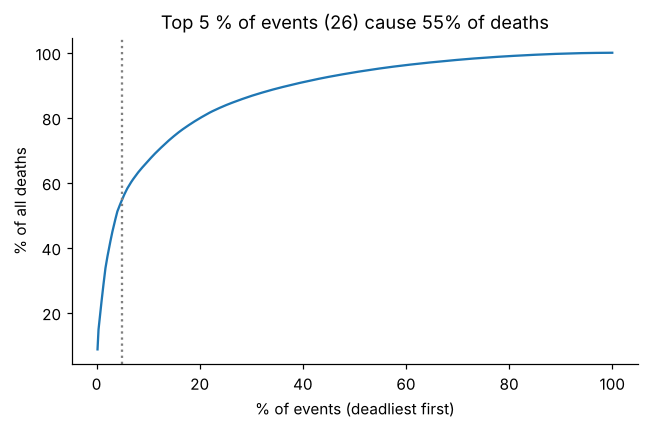

,,year,countries,deaths
event_key,hazard_family,,,
2013-0192,flood,2013,IND,6054.0
2007-0556,tropical_cyclone,2007,BGD,4234.0
2022-0293,flood,2022,IND,2035.0
2010-0341,flood,2010,PAK,1985.0
2020-0304,flood,2020,IND,1922.0
2019-0331,flood,2019,IND,1900.0
2004-0298,flood,2004,"BGD, IND, NPL, PAK",1820.0
2023-0428,flood,2023,"IND, PAK",1746.0


In [14]:
ev_deaths = (imp[imp.impact_type == "death"].groupby("event_key")["impact_value"].sum()
             .sort_values(ascending=False))
share = ev_deaths.cumsum() / ev_deaths.sum()
k = int(np.ceil(0.05 * len(ev_deaths)))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, len(share) + 1) / len(share) * 100, share.values * 100)
ax.axvline(5, ls=":", c="grey")
ax.set(xlabel="% of events (deadliest first)", ylabel="% of all deaths",
       title=f"Top 5 % of events ({k}) cause {share.iloc[k - 1]:.0%} of deaths")
plt.tight_layout(); plt.show()
top = imp[(imp.impact_type == "death") & imp.event_key.isin(ev_deaths.index[:8])]
top.groupby(["event_key", "hazard_family"]).agg(year=("year", "first"), countries=("country", lambda s: ", ".join(sorted(set(s)))),
                                                deaths=("impact_value", "sum")).sort_values("deaths", ascending=False)

## Step 8 — Climate drivers: ENSO and the Indian Ocean Dipole

The Indian summer monsoon is modulated by two ocean–atmosphere modes:

* **ENSO** — El Niño years tend to weaken the monsoon; the relationship has varied over time {cite}`kumar1999`.
* **IOD** — a positive Indian Ocean Dipole tends to strengthen monsoon rainfall and can offset El Niño {cite}`ashok2001`.

We average the NOAA indices over the June–September monsoon season (JJAS) and relate them to
EM-DAT flood counts and to the (log) number of people affected.

,driver,target,Spearman ρ,95% bootstrap CI
0,ONI_JJAS,flood_events,0.12,"[-0.28, 0.48]"
1,ONI_JJAS,log10_affected,-0.07,"[-0.46, 0.36]"
2,DMI_JJAS,flood_events,0.25,"[-0.16, 0.64]"
3,DMI_JJAS,log10_affected,0.02,"[-0.38, 0.41]"


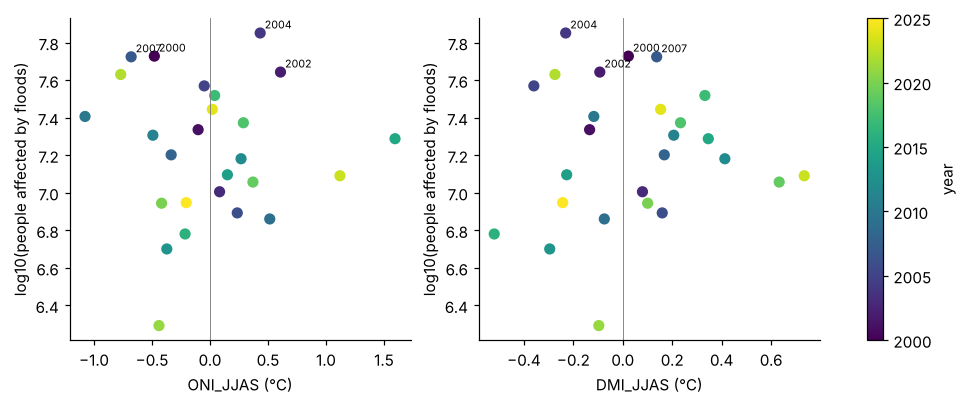

In [15]:
oni, dmi = mu.noaa_index("oni"), mu.noaa_index("dmi")
def jjas(s):
    s = s[s.index.month.isin([6, 7, 8, 9])]
    return s.groupby(s.index.year).mean()

affected = (imp[(imp.impact_type == "affected_total") & (imp.hazard_family == "flood")]
            .groupby("year")["impact_value"].sum().reindex(YEARS).fillna(0))
clim = pd.DataFrame({"ONI_JJAS": jjas(oni), "DMI_JJAS": jjas(dmi),
                     "flood_events": annual["flood"], "log10_affected": np.log10(affected + 1)}).loc[2000:2025].dropna()

def boot_spearman(x, y, n=4000, seed=1):
    rng = np.random.default_rng(seed)
    r = stats.spearmanr(x, y).statistic
    idx = rng.integers(0, len(x), (n, len(x)))
    bs = [stats.spearmanr(x[i], y[i]).statistic for i in idx]
    return r, *np.nanpercentile(bs, [2.5, 97.5])

rows = []
for drv in ["ONI_JJAS", "DMI_JJAS"]:
    for tgt in ["flood_events", "log10_affected"]:
        r, lo, hi = boot_spearman(clim[drv].to_numpy(), clim[tgt].to_numpy())
        rows.append({"driver": drv, "target": tgt, "Spearman ρ": round(r, 2), "95% bootstrap CI": f"[{lo:.2f}, {hi:.2f}]"})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, drv in zip(axes, ["ONI_JJAS", "DMI_JJAS"]):
    sc = ax.scatter(clim[drv], clim["log10_affected"], c=clim.index, cmap="viridis", s=40)
    for yr, row in clim.iterrows():
        if row["log10_affected"] > clim["log10_affected"].quantile(.85):
            ax.annotate(int(yr), (row[drv], row["log10_affected"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.axvline(0, c="grey", lw=.6)
    ax.set(xlabel=f"{drv} (°C)", ylabel="log10(people affected by floods)")
fig.colorbar(sc, ax=axes, label="year"); plt.show()

With only 26 seasons the bootstrap intervals are wide and usually include zero, so ENSO
and IOD **explain only a modest share** of year-to-year flood-disaster variability in this
record. This is consistent with the literature, because impacts depend on *where* the rain
falls (Pakistan in 2010 and 2022, Kerala in 2018) and not only on the regional monsoon total.
Larger signals appear at sub-regional scale; see the exercises.

## Step 9 — Forecasting monthly flood disasters out-of-sample

A model is only useful for planning if it beats a simple benchmark on **data it has not seen**.
We train on 2000–2021 and forecast every month of 2022–2025:

| Model | Predictors |
|-------|-----------|
| Climatology | Average count for each calendar month (the benchmark) |
| NB-GLM | Seasonal harmonics + linear trend |
| NB-GLM + ENSO | Same + ONI observed **3 months earlier** (so the forecast could have been issued in time) |

Forecasts are scored with the mean absolute error (MAE), the mean Poisson deviance (a proper
score for counts), and the coverage of the 80 % predictive interval. We also report the
skill score $1 - \text{MAE}_{model}/\text{MAE}_{clim}$.

,model,MAE,Poisson deviance,80% PI coverage,MAE skill vs clim.
0,Climatology,0.947,1.045,94%,+0.0%
1,NB-GLM,1.014,1.111,94%,-7.0%
2,NB-GLM + ENSO,0.976,1.047,98%,-3.1%


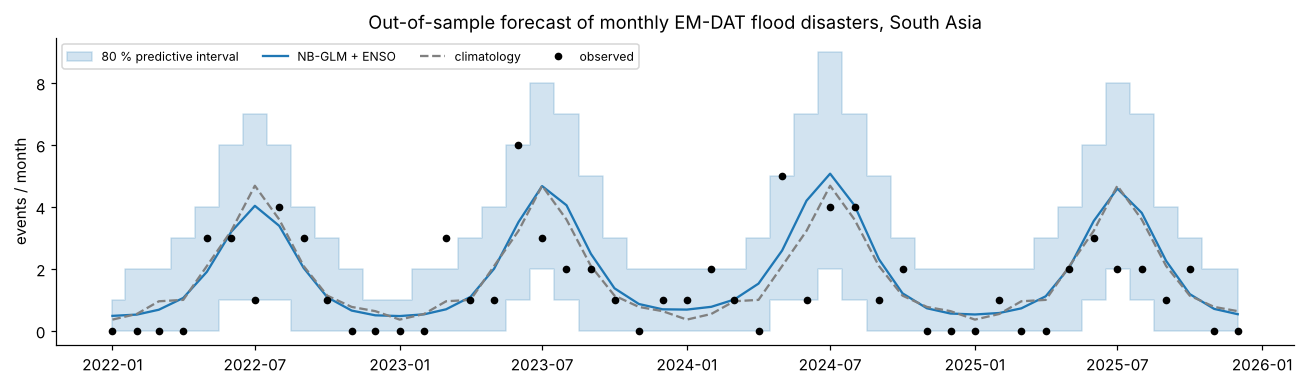

In [16]:
df = monthly.to_frame("y")
df["t"] = np.arange(len(df)) / 120.0
for k in (1, 2):
    df[f"s{k}"] = np.sin(2 * np.pi * k * df.index.month / 12)
    df[f"c{k}"] = np.cos(2 * np.pi * k * df.index.month / 12)
df["oni_lag3"] = oni.reindex(df.index - pd.DateOffset(months=3)).to_numpy()
train, test = df.loc[:"2021-12"], df.loc["2022-01":]

def nb_glm(cols):
    Xtr, Xte = sm.add_constant(train[cols]), sm.add_constant(test[cols])
    alpha = sm.NegativeBinomial(train.y, Xtr).fit(disp=0).params["alpha"]
    fit = sm.GLM(train.y, Xtr, family=sm.families.NegativeBinomial(alpha=alpha)).fit()
    return fit.predict(Xte), alpha

harm = ["s1", "c1", "s2", "c2"]
preds = {"Climatology": test.index.month.map(train.groupby(train.index.month).y.mean()).to_numpy()}
alphas = {"Climatology": None}
preds["NB-GLM"], alphas["NB-GLM"] = nb_glm(harm + ["t"])
preds["NB-GLM + ENSO"], alphas["NB-GLM + ENSO"] = nb_glm(harm + ["t", "oni_lag3"])

def nb_interval(mu_, alpha, q):
    if alpha is None:   # Poisson for the climatology benchmark
        return stats.poisson.ppf(q, mu_)
    n = 1 / alpha
    return stats.nbinom.ppf(q, n, n / (n + mu_))

rows, mae_clim = [], mean_absolute_error(test.y, preds["Climatology"])
for name, p in preds.items():
    p = np.asarray(p, float)
    lo, hi = nb_interval(p, alphas[name], .1), nb_interval(p, alphas[name], .9)
    rows.append({"model": name, "MAE": round(mean_absolute_error(test.y, p), 3),
                 "Poisson deviance": round(mean_poisson_deviance(test.y, np.clip(p, 1e-6, None)), 3),
                 "80% PI coverage": f"{np.mean((test.y >= lo) & (test.y <= hi)):.0%}",
                 "MAE skill vs clim.": f"{1 - mean_absolute_error(test.y, p) / mae_clim:+.1%}"})
display(pd.DataFrame(rows))

best = "NB-GLM + ENSO"
p = np.asarray(preds[best], float)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.fill_between(test.index, nb_interval(p, alphas[best], .1), nb_interval(p, alphas[best], .9),
                color="tab:blue", alpha=.2, step="mid", label="80 % predictive interval")
ax.plot(test.index, p, color="tab:blue", label=best)
ax.plot(test.index, preds["Climatology"], color="grey", ls="--", label="climatology")
ax.plot(test.index, test.y, "ko", ms=4, label="observed")
ax.set(title="Out-of-sample forecast of monthly EM-DAT flood disasters, South Asia", ylabel="events / month")
ax.legend(fontsize=8, ncol=4); plt.tight_layout(); plt.show()

Seasonality carries almost all of the predictable signal, and climatology is a hard benchmark
to beat. The trend term *hurts* out-of-sample because it extrapolates noise. Adding lagged
ENSO recovers part of that loss, but the model still does not beat climatology, so treat small
differences in MAE as noise. The 80 % intervals cover more than 80 % of observations,
i.e. they are conservative: the overdispersion estimated from 2000–2021 is larger than the
variability in 2022–2025. A model that cannot beat climatology out-of-sample should not be used to
argue that a driver "explains" disasters.

## Step 10 — Which countries carry the burden?

Absolute numbers favour large countries; normalising by population shows relative burden.
Rates for small countries (Bhutan has fewer than 1 million inhabitants) rest on very few
events, so a single disaster moves them a lot. Report them with that uncertainty in mind.

In [17]:
pop_latest = pop.sort_values("year").groupby("iso3")["value"].last()
by_country = (mu.explode_countries(em).groupby(["country", "hazard_family"]).size().unstack(fill_value=0))
deaths_c = imp[imp.impact_type == "death"].groupby("country")["impact_value"].sum()
by_country["deaths"] = deaths_c.reindex(by_country.index).fillna(0)
by_country["deaths per million (2000–25)"] = (by_country["deaths"] / pop_latest.reindex(by_country.index) * 1e6).round(1)
by_country.index = by_country.index.map(lambda c: f"{COUNTRIES.get(c, c)} ({c})")
by_country.sort_values("deaths per million (2000–25)", ascending=False)

hazard_family,flood,tropical_cyclone,deaths,deaths per million (2000–25)
country,,,,
Bhutan (BTN),3,1,222.0,280.5
Nepal (NPL),40,0,3637.0,122.7
Sri Lanka (LKA),53,10,2289.0,104.4
Afghanistan (AFG),92,0,4179.0,98.0
Bangladesh (BGD),46,34,8896.0,51.3
Pakistan (PAK),89,3,11622.0,46.3
India (IND),208,46,38602.0,26.6
Maldives (MDV),2,1,0.0,0.0


## Summary

:::{admonition} Key findings
:class: tip
1. **Coverage first.** South-Asian flood counts per source jump with catalogue changes (GDACS gap
   2015–18, IDMC expansion after 2018, DesInventar ending 2020). Pooling sources manufactures trends.
2. **Seasonality is the dominant signal.** Floods peak in the monsoon; cyclone disasters are bimodal
   around the monsoon onset and withdrawal.
3. **Trends in event counts are not robust.** Count-appropriate models with autocorrelation-aware tests give
   wide intervals that include "no change".
4. **Impacts are heavy-tailed and per-capita mortality is flat.** A few catastrophes dominate deaths; mortality
   per million shows no decline since 2000 in this record, unlike the global decline reported in the literature.
5. **ENSO/IOD** add little predictive skill at regional, annual scale; monthly forecasts barely beat climatology.
:::

:::{admonition} Try it yourself
:class: note
* Repeat Step 8 for **Pakistan only** or **Bangladesh only**: are teleconnections stronger at country scale?
* Swap EM-DAT for **IDMC** (displacement) and restrict to 2018–2025, when its coverage is stable.
* Replace the linear trend in Step 9 with a monsoon-rainfall covariate (e.g. NASA POWER precipitation).
:::

```{bibliography}
:filter: docname in docnames
```